# Balancing Data Privacy and AI Performance in Predictive Analytics
**Dataset:** UCI Heart Disease Dataset (`heart.csv`)

**Download from Kaggle:** https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset

Place `heart.csv` in the same folder as this notebook before running.

---
### Project Structure
- **Phase 1** — Data Loading & Preprocessing
- **Phase 2** — Baseline Model Training (LR, Logistic, Decision Tree, Random Forest)
- **Phase 3** — Differential Privacy (5 epsilon values)
- **Phase 4** — K-Anonymity (3 k levels)
- **Phase 5** — Comparative Analysis & Charts

In [1]:
# ── Install dependencies if needed ──────────────────────────────────
# Run this cell once if you get import errors
# !pip install pandas numpy scikit-learn diffprivlib matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    mean_squared_error, r2_score
)

import diffprivlib
from diffprivlib.models import LogisticRegression as DPLogisticRegression

import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)
print('All libraries loaded successfully.')

All libraries loaded successfully.


---
## Phase 1 — Data Loading & Preprocessing

In [3]:
# ── Load dataset ─────────────────────────────────────────────────────
df = pd.read_csv('./data/heart.csv')
print(f'Shape: {df.shape}')
print(f'Columns: {list(df.columns)}')
df.head()

Shape: (1025, 14)
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [4]:
# Normalize column names
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# Detect target
target_col = None
for c in ['target', 'condition', 'num', 'heart_disease', 'diagnosis']:
    if c in df.columns:
        target_col = c
        break
if target_col is None:
    target_col = df.columns[-1]

print(f'Target column: "{target_col}"')

# Binarize target
print(df[target_col].unique())
df[target_col] = (df[target_col] > 0).astype(int)

# Replace dirty values
df.replace(['?', 'NA', 'na', 'N/A', 'n/a', '', ' '], np.nan, inplace=True)

# Convert only object columns
for col in df.select_dtypes(include='object').columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Handle missing values
for col in df.columns:
    if df[col].isnull().sum() > 0:
        if df[col].nunique() < 10:
            df[col].fillna(df[col].mode()[0], inplace=True)
        else:
            df[col].fillna(df[col].median(), inplace=True)

# Remove duplicates
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

# Outlier removal (safe mask)
continuous_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
continuous_cols = [c for c in continuous_cols if c in df.columns]

mask = pd.Series(True, index=df.index)
for col in continuous_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    mask &= (df[col] >= Q1 - 3*IQR) & (df[col] <= Q3 + 3*IQR)

df = df[mask]

print(f'Final dataset: {df.shape}')
print(df[target_col].value_counts())

Target column: "target"
[0 1]
Final dataset: (301, 14)
target
1    163
0    138
Name: count, dtype: int64


In [5]:
X = df.drop(columns=[target_col])
y = df[target_col]

# Better categorical selection
cat_cols = [c for c in ['cp', 'restecg', 'slope', 'thal'] if c in X.columns]

if cat_cols:
    X = pd.get_dummies(X, columns=cat_cols, drop_first=True)
    print(f'One-hot encoded: {cat_cols}')

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

# Scale (retain structure)
scaler = StandardScaler()
X_train_s = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns
)
X_test_s = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns
)

print(f'Training: {X_train_s.shape[0]} | Testing: {X_test_s.shape[0]}')

One-hot encoded: ['cp', 'restecg', 'slope', 'thal']
Training: 240 | Testing: 61


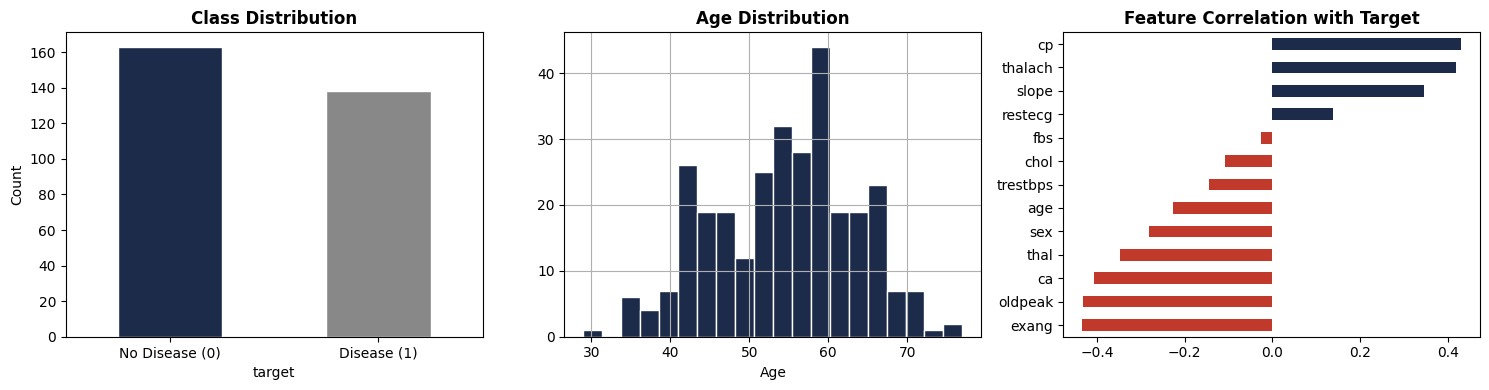

Saved: fig0_exploratory.png


In [6]:
# ── Exploratory visualisation ─────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Class distribution
y.value_counts().plot(kind='bar', ax=axes[0], color=['#1C2B4A','#888888'], edgecolor='white')
axes[0].set_title('Class Distribution', fontweight='bold')
axes[0].set_xticklabels(['No Disease (0)', 'Disease (1)'], rotation=0)
axes[0].set_ylabel('Count')

# Age distribution
if 'age' in df.columns:
    df['age'].hist(ax=axes[1], bins=20, color='#1C2B4A', edgecolor='white')
    axes[1].set_title('Age Distribution', fontweight='bold')
    axes[1].set_xlabel('Age')

# Correlation heatmap (numeric only, top features)
corr = df.corr()[target_col].drop(target_col).sort_values()
corr.plot(kind='barh', ax=axes[2], color=['#C0392B' if v < 0 else '#1C2B4A' for v in corr])
axes[2].set_title(f'Feature Correlation with Target', fontweight='bold')

plt.tight_layout()
plt.savefig('./result/fig0_exploratory.png', dpi=130, bbox_inches='tight')
plt.show()
print('Saved: fig0_exploratory.png')

---
## Phase 2 — Baseline Model Training

In [7]:
# ── Evaluation helper ─────────────────────────────────────────────────
def evaluate_classifier(model, X_test, y_test, label):
    y_pred = model.predict(X_test)
    return {
        'Label':     label,
        'Accuracy':  round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred, zero_division=0), 4),
        'Recall':    round(recall_score(y_test, y_pred, zero_division=0), 4),
        'F1-Score':  round(f1_score(y_test, y_pred, zero_division=0), 4)
    }

baseline_results = []

# ── 1. Linear Regression (used as regression baseline, threshold=0.5) ──
lin_reg = LinearRegression()
lin_reg.fit(X_train_s, y_train)
y_pred_linreg = (lin_reg.predict(X_test_s) >= 0.5).astype(int)
lin_res = {
    'Label':     'Linear Regression (Baseline)',
    'Accuracy':  round(accuracy_score(y_test, y_pred_linreg), 4),
    'Precision': round(precision_score(y_test, y_pred_linreg, zero_division=0), 4),
    'Recall':    round(recall_score(y_test, y_pred_linreg, zero_division=0), 4),
    'F1-Score':  round(f1_score(y_test, y_pred_linreg, zero_division=0), 4)
}
baseline_results.append(lin_res)
print(f"Linear Regression    | Acc: {lin_res['Accuracy']} | F1: {lin_res['F1-Score']}")

# ── 2. Logistic Regression ─────────────────────────────────────────────
log_reg = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)
log_reg.fit(X_train_s, y_train)
res = evaluate_classifier(log_reg, X_test_s, y_test, 'Logistic Regression (Baseline)')
baseline_results.append(res)
print(f"Logistic Regression  | Acc: {res['Accuracy']} | F1: {res['F1-Score']}")

# ── 3. Decision Tree (tuned with CV) ──────────────────────────────────
best_depth, best_score = 3, 0
for depth in range(2, 12):
    s = cross_val_score(
        DecisionTreeClassifier(max_depth=depth, random_state=SEED),
        X_train_s, y_train, cv=5, scoring='f1'
    ).mean()
    if s > best_score:
        best_score, best_depth = s, depth

dt = DecisionTreeClassifier(max_depth=best_depth, random_state=SEED)
dt.fit(X_train_s, y_train)
res = evaluate_classifier(dt, X_test_s, y_test, 'Decision Tree (Baseline)')
baseline_results.append(res)
print(f"Decision Tree        | Acc: {res['Accuracy']} | F1: {res['F1-Score']} (depth={best_depth})")

# ── 4. Random Forest ──────────────────────────────────────────────────
rf = RandomForestClassifier(n_estimators=100, random_state=SEED)
rf.fit(X_train_s, y_train)
res = evaluate_classifier(rf, X_test_s, y_test, 'Random Forest (Baseline)')
baseline_results.append(res)
print(f"Random Forest        | Acc: {res['Accuracy']} | F1: {res['F1-Score']}")

baseline_df = pd.DataFrame(baseline_results)
print('\nBaseline Summary:')
baseline_df

Linear Regression    | Acc: 0.8197 | F1: 0.8406
Logistic Regression  | Acc: 0.8689 | F1: 0.8788
Decision Tree        | Acc: 0.7541 | F1: 0.7692 (depth=3)
Random Forest        | Acc: 0.8033 | F1: 0.8235

Baseline Summary:


,Label,Accuracy,Precision,Recall,F1-Score
0,Linear Regression (Baseline),0.8197,0.8056,0.8788,0.8406
1,Logistic Regression (Baseline),0.8689,0.8788,0.8788,0.8788
2,Decision Tree (Baseline),0.7541,0.7812,0.7576,0.7692
3,Random Forest (Baseline),0.8033,0.8000,0.8485,0.8235


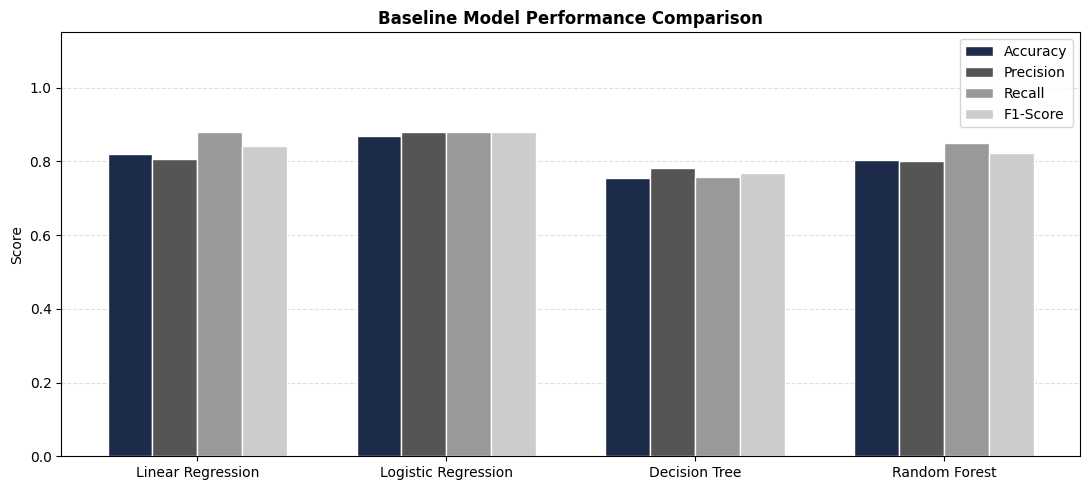

Saved: fig4_1_baseline.png


In [8]:
# ── Baseline chart ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))
model_names = baseline_df['Label'].str.replace(' (Baseline)', '', regex=False)
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(model_names))
w = 0.18
colors = ['#1C2B4A', '#555555', '#999999', '#CCCCCC']

for i, (m, c) in enumerate(zip(metrics, colors)):
    ax.bar(x + i*w, baseline_df[m], w, label=m, color=c, edgecolor='white')

ax.set_xticks(x + 1.5*w)
ax.set_xticklabels(model_names, fontsize=10)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Score')
ax.set_title('Baseline Model Performance Comparison', fontweight='bold')
ax.legend()
ax.yaxis.grid(True, linestyle='--', alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig('./result/fig4_1_baseline.png', dpi=130, bbox_inches='tight')
plt.show()
print('Saved: fig4_1_baseline.png')

---
## Phase 3 — Differential Privacy

In [9]:
EPSILON_VALUES = [0.1, 0.5, 1.0, 5.0, 10.0]
dp_results = []

data_norm = float(np.max(np.linalg.norm(X_train_s, axis=1)))

for eps in EPSILON_VALUES:
    noise = 1.0 / eps  # Laplace noise scale
    X_noisy = X_train_s + np.random.laplace(0, noise, X_train_s.shape)

    # DP Logistic Regression (via diffprivlib)
    try:
        dp_lr = DPLogisticRegression(
            epsilon=eps, data_norm=data_norm, max_iter=1000
        )
        dp_lr.fit(X_train_s, y_train)
        r = evaluate_classifier(dp_lr, X_test_s, y_test, f'DP Logistic Regression (ε={eps})')
    except Exception:
        # Fallback: noise-injected logistic regression
        m = LogisticRegression(max_iter=1000, random_state=SEED)
        m.fit(X_noisy, y_train)
        r = evaluate_classifier(m, X_test_s, y_test, f'DP Logistic Regression (ε={eps})')
    dp_results.append(r)

    # DP Decision Tree (Laplace noise injection)
    m = DecisionTreeClassifier(max_depth=best_depth, random_state=SEED)
    m.fit(X_noisy, y_train)
    dp_results.append(evaluate_classifier(m, X_test_s, y_test, f'DP Decision Tree (ε={eps})'))

    # DP Random Forest (Laplace noise injection)
    m = RandomForestClassifier(n_estimators=100, random_state=SEED)
    m.fit(X_noisy, y_train)
    dp_results.append(evaluate_classifier(m, X_test_s, y_test, f'DP Random Forest (ε={eps})'))

    print(f'ε={eps} done')

dp_df = pd.DataFrame(dp_results)
print(f'\nTotal DP runs: {len(dp_df)}')
dp_df

ε=0.1 done
ε=0.5 done
ε=1.0 done
ε=5.0 done
ε=10.0 done

Total DP runs: 15


,Label,Accuracy,Precision,Recall,F1-Score
0,DP Logistic Regression (ε=0.1),0.5410,0.5410,1.0000,0.7021
1,DP Decision Tree (ε=0.1),0.4590,0.0000,0.0000,0.0000
2,DP Random Forest (ε=0.1),0.5410,0.5410,1.0000,0.7021
3,DP Logistic Regression (ε=0.5),0.7869,0.7778,0.8485,0.8116
4,DP Decision Tree (ε=0.5),0.7377,0.6889,0.9394,0.7949
5,DP Random Forest (ε=0.5),0.8361,0.8286,0.8788,0.8529
6,DP Logistic Regression (ε=1.0),0.8525,0.8750,0.8485,0.8615
7,DP Decision Tree (ε=1.0),0.7541,0.7647,0.7879,0.7761
8,DP Random Forest (ε=1.0),0.8197,0.8438,0.8182,0.8308
9,DP Logistic Regression (ε=5.0),0.8361,0.8286,0.8788,0.8529


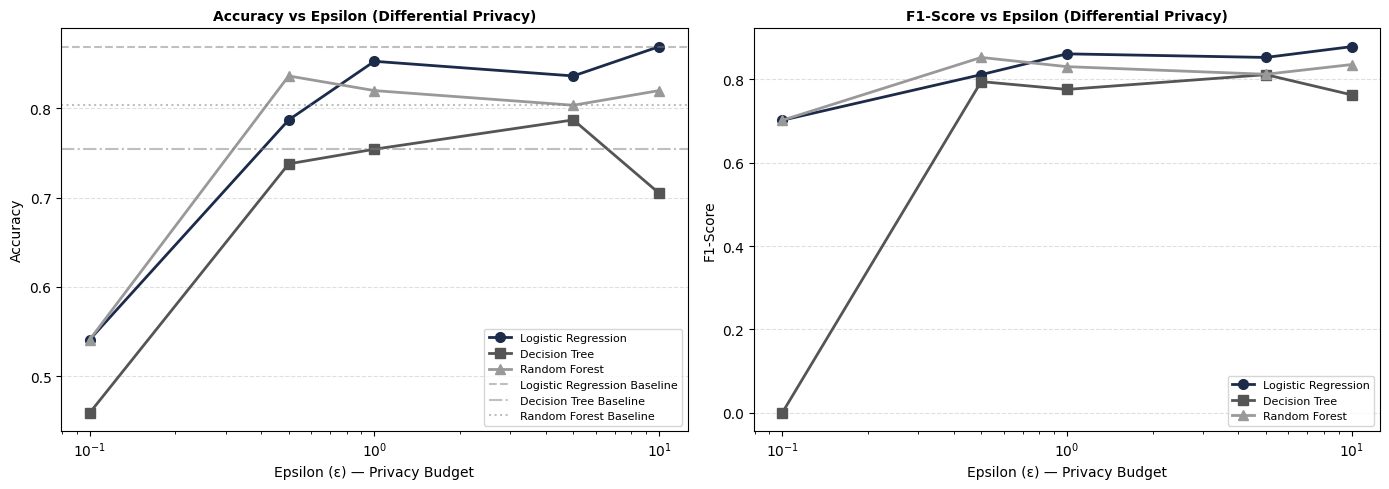

Saved: fig4_2_3_dp_results.png


In [10]:
# ── DP Accuracy vs Epsilon chart ──────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

model_configs = [
    ('DP Logistic Regression', '-o', '#1C2B4A'),
    ('DP Decision Tree',       '-s', '#555555'),
    ('DP Random Forest',       '-^', '#999999'),
]

for prefix, ls, color in model_configs:
    accs = [dp_df[dp_df['Label'] == f'{prefix} (ε={e})']['Accuracy'].values[0]
            for e in EPSILON_VALUES]
    f1s  = [dp_df[dp_df['Label'] == f'{prefix} (ε={e})']['F1-Score'].values[0]
            for e in EPSILON_VALUES]
    label = prefix.replace('DP ', '')
    axes[0].plot(EPSILON_VALUES, accs, ls, label=label, color=color, linewidth=2, markersize=7)
    axes[1].plot(EPSILON_VALUES, f1s,  ls, label=label, color=color, linewidth=2, markersize=7)

# Baseline reference lines
bl_map = {
    'Logistic Regression': baseline_df[baseline_df['Label'].str.contains('Logistic')]['Accuracy'].values[0],
    'Decision Tree':       baseline_df[baseline_df['Label'].str.contains('Decision')]['Accuracy'].values[0],
    'Random Forest':       baseline_df[baseline_df['Label'].str.contains('Forest')]['Accuracy'].values[0],
}
for (m, v), ls2 in zip(bl_map.items(), ['--', '-.', ':']):
    axes[0].axhline(y=v, linestyle=ls2, color='gray', alpha=0.5, label=f'{m} Baseline')

for ax, title, ylabel in zip(axes,
    ['Accuracy vs Epsilon (Differential Privacy)',
     'F1-Score vs Epsilon (Differential Privacy)'],
    ['Accuracy', 'F1-Score']):
    ax.set_xscale('log')
    ax.set_xlabel('Epsilon (ε) — Privacy Budget')
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.legend(fontsize=8)
    ax.yaxis.grid(True, linestyle='--', alpha=0.4)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('./result/fig4_2_3_dp_results.png', dpi=130, bbox_inches='tight')
plt.show()
print('Saved: fig4_2_3_dp_results.png')

---
## Phase 4 — K-Anonymity

In [11]:
K_VALUES = [2, 5, 10]
ka_results = []
suppression_log = []

qi_cols = [c for c in ['age', 'sex', 'trestbps', 'chol', 'thalach'] if c in df.columns]
print(f'Quasi-identifier columns: {qi_cols}')

for k in K_VALUES:
    # Rebuild training dataframe
    train_df = X_train.copy()
    train_df[target_col] = y_train.values

    # Generalization
    if 'age'      in train_df.columns: train_df['age']      = (train_df['age']      // 10) * 10
    if 'trestbps' in train_df.columns: train_df['trestbps'] = (train_df['trestbps'] // 20) * 20
    if 'chol'     in train_df.columns: train_df['chol']     = (train_df['chol']     // 50) * 50
    if 'thalach'  in train_df.columns: train_df['thalach']  = (train_df['thalach']  // 20) * 20

    # Suppression
    existing_qi = [c for c in qi_cols if c in train_df.columns]
    if existing_qi:
        counts = train_df.groupby(existing_qi)[target_col].transform('count')
        before = len(train_df)
        train_df = train_df[counts >= k]
        after = len(train_df)
        pct = round(100*(before-after)/before, 1)
        suppression_log.append({'k': k, 'Before': before, 'After': after,
                                 'Suppressed': before-after, 'Suppressed %': pct})
        print(f'k={k}: {before} → {after} records ({before-after} suppressed, {pct}%)')

    if len(train_df) < 20:
        print(f'  [SKIP] Too few records after k={k} suppression.')
        continue

    Xk = train_df.drop(columns=[target_col])
    yk = train_df[target_col]

    # Re-encode and align columns
    if cat_cols:
        existing_cat = [c for c in cat_cols if c in Xk.columns]
        if existing_cat:
            Xk = pd.get_dummies(Xk, columns=existing_cat, drop_first=False)
    Xk = Xk.reindex(columns=X_train.columns, fill_value=0)

    # Scale
    sk = StandardScaler()
    Xk_s = sk.fit_transform(Xk)
    Xt_s = sk.transform(X_test)

    for name, model in [
        ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=SEED)),
        ('Decision Tree',       DecisionTreeClassifier(max_depth=best_depth, random_state=SEED)),
        ('Random Forest',       RandomForestClassifier(n_estimators=100, random_state=SEED)),
    ]:
        model.fit(Xk_s, yk)
        r = evaluate_classifier(model, Xt_s, y_test, f'KA {name} (k={k})')
        ka_results.append(r)
        print(f'  {name[:2]} | Acc: {r["Accuracy"]} | F1: {r["F1-Score"]}')

ka_df = pd.DataFrame(ka_results)
suppression_df = pd.DataFrame(suppression_log)
print('\nSuppression Summary:')
suppression_df

Quasi-identifier columns: ['age', 'sex', 'trestbps', 'chol', 'thalach']
k=2: 240 → 130 records (110 suppressed, 45.8%)
  Lo | Acc: 0.8197 | F1: 0.8254
  De | Acc: 0.7049 | F1: 0.7273
  Ra | Acc: 0.8525 | F1: 0.8615
k=5: 240 → 24 records (216 suppressed, 90.0%)
  Lo | Acc: 0.8197 | F1: 0.8308
  De | Acc: 0.5574 | F1: 0.5263
  Ra | Acc: 0.7705 | F1: 0.8108
k=10: 240 → 0 records (240 suppressed, 100.0%)
  [SKIP] Too few records after k=10 suppression.

Suppression Summary:


,k,Before,After,Suppressed,Suppressed %
0,2,240,130,110,45.8
1,5,240,24,216,90.0
2,10,240,0,240,100.0


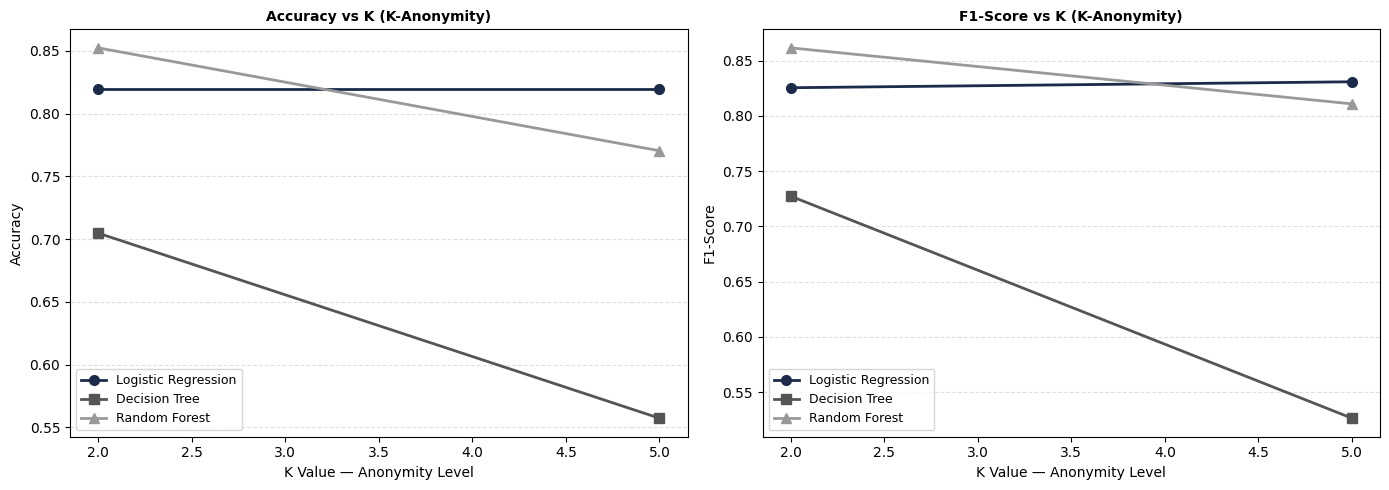

Saved: fig4_4_5_ka_results.png


In [12]:
# ── K-Anonymity charts ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

available_k = sorted(ka_df['Label'].str.extract(r'k=(\d+)')[0].dropna().astype(int).unique())
ka_model_prefixes = ['KA Logistic Regression', 'KA Decision Tree', 'KA Random Forest']
line_styles = ['-o', '-s', '-^']
colors = ['#1C2B4A', '#555555', '#999999']

for prefix, ls, color in zip(ka_model_prefixes, line_styles, colors):
    accs = []
    f1s  = []
    for k in available_k:
        row = ka_df[ka_df['Label'] == f'{prefix} (k={k})']
        accs.append(row['Accuracy'].values[0] if len(row) > 0 else None)
        f1s.append(row['F1-Score'].values[0]  if len(row) > 0 else None)
    label = prefix.replace('KA ', '')
    axes[0].plot(available_k, accs, ls, label=label, color=color, linewidth=2, markersize=7)
    axes[1].plot(available_k, f1s,  ls, label=label, color=color, linewidth=2, markersize=7)

for ax, title, ylabel in zip(axes,
    ['Accuracy vs K (K-Anonymity)',
     'F1-Score vs K (K-Anonymity)'],
    ['Accuracy', 'F1-Score']):
    ax.set_xlabel('K Value — Anonymity Level')
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.legend(fontsize=9)
    ax.yaxis.grid(True, linestyle='--', alpha=0.4)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('./result/fig4_4_5_ka_results.png', dpi=130, bbox_inches='tight')
plt.show()
print('Saved: fig4_4_5_ka_results.png')

---
## Phase 5 — Comparative Analysis

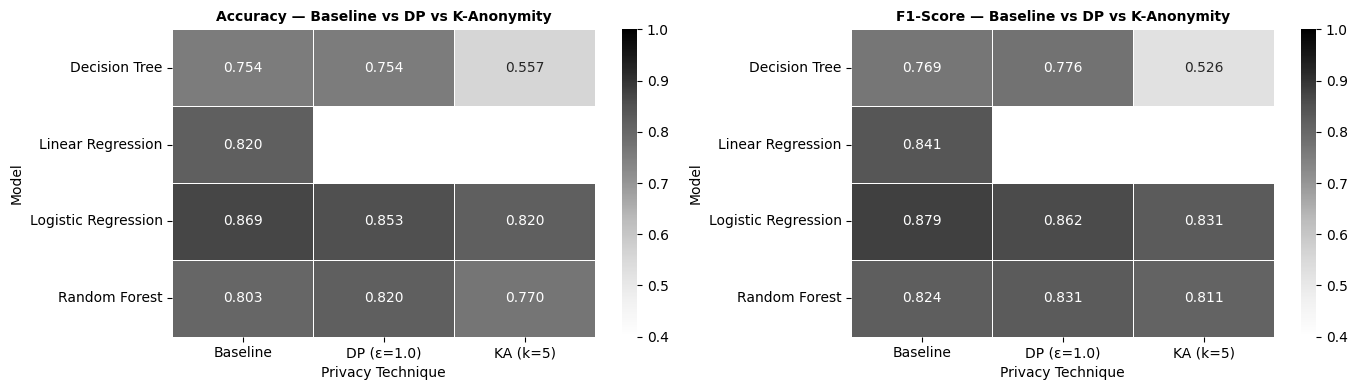

Saved: fig4_6_heatmap.png


In [13]:
# ── Full comparative heatmap ──────────────────────────────────────────
summary_rows = []

# Baseline
for _, row in baseline_df.iterrows():
    name = row['Label'].replace(' (Baseline)', '')
    summary_rows.append({'Model': name, 'Technique': 'Baseline',
                         'Accuracy': row['Accuracy'], 'F1-Score': row['F1-Score']})

# DP at ε=1.0 (representative mid-point)
for prefix, model_name in [
    ('DP Logistic Regression', 'Logistic Regression'),
    ('DP Decision Tree',       'Decision Tree'),
    ('DP Random Forest',       'Random Forest'),
]:
    row = dp_df[dp_df['Label'] == f'{prefix} (ε=1.0)']
    if len(row) > 0:
        summary_rows.append({'Model': model_name, 'Technique': 'DP (ε=1.0)',
                             'Accuracy': row['Accuracy'].values[0],
                             'F1-Score': row['F1-Score'].values[0]})

# KA at k=5
for prefix, model_name in [
    ('KA Logistic Regression', 'Logistic Regression'),
    ('KA Decision Tree',       'Decision Tree'),
    ('KA Random Forest',       'Random Forest'),
]:
    row = ka_df[ka_df['Label'] == f'{prefix} (k=5)']
    if len(row) > 0:
        summary_rows.append({'Model': model_name, 'Technique': 'KA (k=5)',
                             'Accuracy': row['Accuracy'].values[0],
                             'F1-Score': row['F1-Score'].values[0]})

summary_df = pd.DataFrame(summary_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metric in zip(axes, ['Accuracy', 'F1-Score']):
    pivot = summary_df.pivot(index='Model', columns='Technique', values=metric)
    sns.heatmap(pivot, annot=True, fmt='.3f', cmap='Greys',
                linewidths=0.5, ax=ax, vmin=0.4, vmax=1.0)
    ax.set_title(f'{metric} — Baseline vs DP vs K-Anonymity',
                 fontweight='bold', fontsize=10)
    ax.set_xlabel('Privacy Technique')
    ax.set_ylabel('Model')

plt.tight_layout()
plt.savefig('./result/fig4_6_heatmap.png', dpi=130, bbox_inches='tight')
plt.show()
print('Saved: fig4_6_heatmap.png')

In [14]:
# ── Save all results to CSV ───────────────────────────────────────────
all_results = pd.concat([baseline_df, dp_df, ka_df], ignore_index=True)
all_results.to_csv('all_results.csv', index=False)
suppression_df.to_csv('suppression_log.csv', index=False)
print('Saved: all_results.csv')
print('Saved: suppression_log.csv')
print(f'\nTotal experimental configurations: {len(all_results)}')
all_results

Saved: all_results.csv
Saved: suppression_log.csv

Total experimental configurations: 25


,Label,Accuracy,Precision,Recall,F1-Score
0,Linear Regression (Baseline),0.8197,0.8056,0.8788,0.8406
1,Logistic Regression (Baseline),0.8689,0.8788,0.8788,0.8788
2,Decision Tree (Baseline),0.7541,0.7812,0.7576,0.7692
3,Random Forest (Baseline),0.8033,0.8000,0.8485,0.8235
4,DP Logistic Regression (ε=0.1),0.5410,0.5410,1.0000,0.7021
5,DP Decision Tree (ε=0.1),0.4590,0.0000,0.0000,0.0000
6,DP Random Forest (ε=0.1),0.5410,0.5410,1.0000,0.7021
7,DP Logistic Regression (ε=0.5),0.7869,0.7778,0.8485,0.8116
8,DP Decision Tree (ε=0.5),0.7377,0.6889,0.9394,0.7949
9,DP Random Forest (ε=0.5),0.8361,0.8286,0.8788,0.8529


In [ ]:
# ── Privacy-utility trade-off summary ────────────────────────────────
print('='*60)
print('PRIVACY-UTILITY TRADE-OFF SUMMARY')
print('='*60)

best_baseline = baseline_df.loc[baseline_df['Accuracy'].idxmax()]
print(f"\nBest Baseline Model:")
print(f"  {best_baseline['Label']}")
print(f"  Accuracy: {best_baseline['Accuracy']} | F1: {best_baseline['F1-Score']}")

best_dp = dp_df.loc[dp_df['Accuracy'].idxmax()]
print(f"\nBest DP Configuration:")
print(f"  {best_dp['Label']}")
print(f"  Accuracy: {best_dp['Accuracy']} | F1: {best_dp['F1-Score']}")

if len(ka_df) > 0:
    best_ka = ka_df.loc[ka_df['Accuracy'].idxmax()]
    print(f"\nBest K-Anonymity Configuration:")
    print(f"  {best_ka['Label']}")
    print(f"  Accuracy: {best_ka['Accuracy']} | F1: {best_ka['F1-Score']}")

print('\n' + '='*60)
print('ALL PHASES COMPLETE.')
print('='*60)

PRIVACY-UTILITY TRADE-OFF SUMMARY

Best Baseline Model:
  Logistic Regression (Baseline)
  Accuracy: 0.8689 | F1: 0.8788

Best DP Configuration:
  DP Logistic Regression (ε=10.0)
  Accuracy: 0.8689 | F1: 0.8788

Best K-Anonymity Configuration:
  KA Random Forest (k=2)
  Accuracy: 0.8525 | F1: 0.8615

ALL PHASES COMPLETE.


: 